In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

ModuleNotFoundError: No module named 'sklearn'

In [2]:
!pip install scikit-learn

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import pairwise_distances

ModuleNotFoundError: No module named 'sklearn'

In [4]:
!pip install scikit-learn

In [5]:
from sklearn.preprocessing import StandardScaler

ModuleNotFoundError: No module named 'sklearn'

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
import sys
!{sys.executable} -m pip install scikit-learn

In [1]:
from sklearn.preprocessing import StandardScaler

print("Scikit-learn imported successfully!")

ModuleNotFoundError: No module named 'sklearn'

In [2]:
import sys
print(sys.executable)

C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\python.exe


In [3]:
import sys
!{sys.executable} -m pip install scikit-learn

  Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl.metadata (9.3 kB)
  Using cached joblib-1.6.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached cloudpickle-3.1.2-py3-none-any.whl.metadata (7.1 kB)
Using cached scikit_learn-1.9.1-cp314-cp314-win_amd64.whl (8.4 MB)
Using cached joblib-1.6.0-py3-none-any.whl (306 kB)
Using cached cloudpickle-3.1.2-py3-none-any.whl (22 kB)

   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1/3 [joblib]
   ------------- -------------------------- 1


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: C:\Users\HP\AppData\Local\Python\pythoncore-3.14-64\python.exe -m pip install --upgrade pip


In [1]:
from sklearn.preprocessing import StandardScaler

print("Scikit-learn imported successfully!")

Scikit-learn imported successfully!


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

In [4]:
db = pd.read_csv("Diabetes.csv")

In [5]:
db.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [6]:
db.shape

(768, 9)

In [7]:
zero_counts = (db == 0).sum()
zero_counts

Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [8]:
invalid_columns = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']

(db[invalid_columns] == 0).sum()

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

In [9]:
db[invalid_columns].isnull().sum()

Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
dtype: int64

In [10]:
(db == 0).sum()

Pregnancies                 111
Glucose                       0
BloodPressure                 0
SkinThickness                 0
Insulin                       0
BMI                           0
DiabetesPedigreeFunction      0
Age                           0
Outcome                     500
dtype: int64

In [11]:
#Calculate correlation matrix
correlation_matrix = db.corr()

correlation_matrix

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
Pregnancies,1.000000,0.130155,0.209151,0.089028,0.058767,0.023890,-0.033523,0.544341,0.221898
Glucose,0.130155,1.000000,0.225141,0.229289,0.490015,0.236171,0.138353,0.268910,0.495990
BloodPressure,0.209151,0.225141,1.000000,0.199349,0.070128,0.286399,-0.001443,0.325135,0.174469
SkinThickness,0.089028,0.229289,0.199349,1.000000,0.200129,0.566086,0.106280,0.129537,0.295138
Insulin,0.058767,0.490015,0.070128,0.200129,1.000000,0.238443,0.146878,0.123629,0.377081
BMI,0.023890,0.236171,0.286399,0.566086,0.238443,1.000000,0.152771,0.027849,0.315577
DiabetesPedigreeFunction,-0.033523,0.138353,-0.001443,0.106280,0.146878,0.152771,1.000000,0.033561,0.173844
Age,0.544341,0.268910,0.325135,0.129537,0.123629,0.027849,0.033561,1.000000,0.238356
Outcome,0.221898,0.495990,0.174469,0.295138,0.377081,0.315577,0.173844,0.238356,1.000000


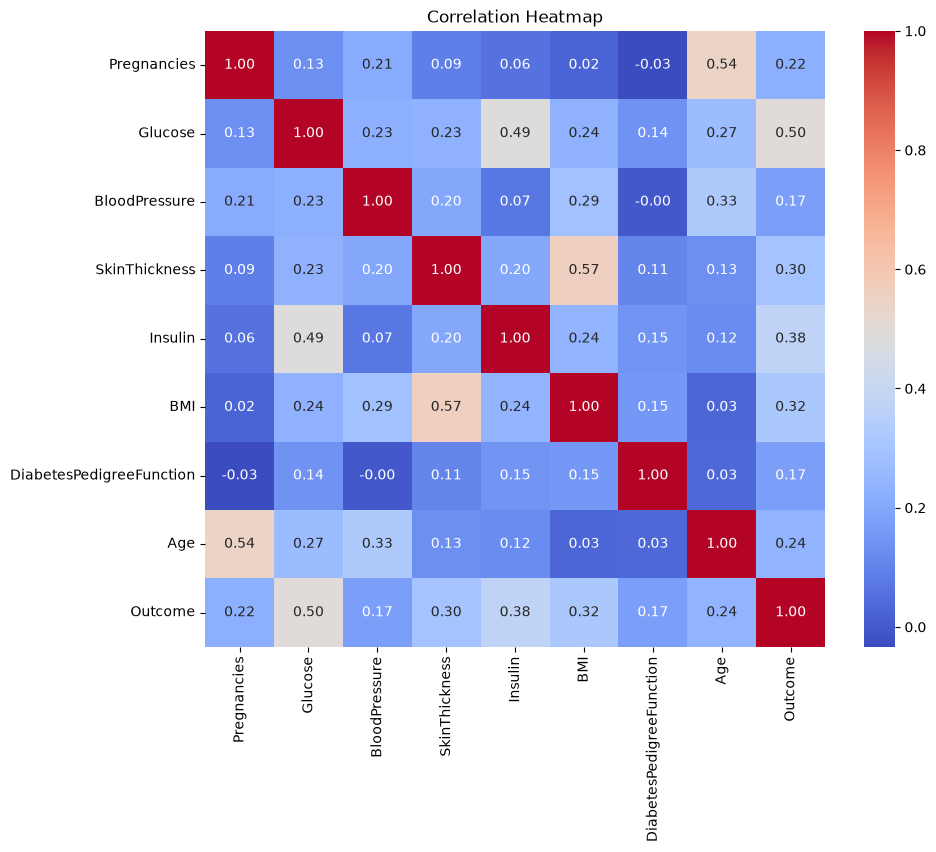

In [12]:
#Heatmap
plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap')
plt.show()

In [13]:
features = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age'
]

x = db.loc[0, features].values
y = db.loc[1, features].values

print("Observation 1:", x)
print("Observation 2:", y)

Observation 1: [  6.    148.     72.     35.    169.5    33.6     0.627  50.   ]
Observation 2: [  1.     85.     66.     29.    102.5    26.6     0.351  31.   ]


In [14]:
#Eucledian distance
euclidean_distance = np.sqrt(np.sum((x - y) ** 2))

print("Euclidean Distance:", euclidean_distance)

Euclidean Distance: 94.68408618136418


In [16]:
#Manhattan distance 
manhattan_distance = np.sum(np.abs(x - y))

print("Manhattan Distance:", manhattan_distance)

Manhattan Distance: 173.276


In [17]:
#Cosine distance 
from sklearn.metrics.pairwise import cosine_distances

cosine_distance = cosine_distances([x], [y])[0][0]

print("Cosine Distance:", cosine_distance)

Cosine Distance: 0.012229531956842177


In [18]:
scaler = StandardScaler()

In [19]:
#Standardizing the data
scaled_data = scaler.fit_transform(db[features])

In [20]:
scaled_db = pd.DataFrame(
    scaled_data,
    columns=features
)

In [21]:
scaled_db.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,0.639947,0.864625,-0.032180,0.665181,0.311604,0.169483,0.468492,1.425995
1,-0.844885,-1.204727,-0.528124,-0.010112,-0.440843,-0.848549,-0.365061,-0.190672
2,1.233880,2.014265,-0.693438,0.327535,0.311604,-1.328478,0.604397,-0.105584
3,-0.844885,-1.073339,-0.528124,-0.685405,-0.536303,-0.630399,-0.920763,-1.041549
4,-1.141852,0.503310,-2.677212,0.665181,0.294758,1.551096,5.484909,-0.020496


In [22]:
#Verify Standardization
scaled_db.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
count,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02,7.680000e+02
mean,-6.476301e-17,1.480297e-16,-3.978299e-16,8.095376e-18,-3.469447e-18,1.318390e-16,2.451743e-16,1.931325e-16
std,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00,1.000652e+00
min,-1.141852e+00,-2.551447e+00,-3.999727e+00,-2.486187e+00,-1.434747e+00,-2.070186e+00,-1.189553e+00,-1.041549e+00
25%,-8.448851e-01,-7.202356e-01,-6.934382e-01,-4.603073e-01,-4.408430e-01,-7.176590e-01,-6.889685e-01,-7.862862e-01
50%,-2.509521e-01,-1.536274e-01,-3.218035e-02,-1.226607e-01,-4.408430e-01,-5.593870e-02,-3.001282e-01,-3.608474e-01
75%,6.399473e-01,6.100618e-01,6.290775e-01,3.275348e-01,3.116039e-01,6.057816e-01,4.662269e-01,6.602056e-01
max,3.906578e+00,2.539814e+00,4.100681e+00,7.868309e+00,7.909072e+00,5.041489e+00,5.883565e+00,4.063716e+00


In [23]:
x_scaled = scaled_db.loc[0].values
y_scaled = scaled_db.loc[1].values

euclidean_scaled = np.sqrt(np.sum((x_scaled - y_scaled) ** 2))
manhattan_scaled = np.sum(np.abs(x_scaled - y_scaled))
cosine_scaled = cosine_distances([x_scaled], [y_scaled])[0][0]

print("Euclidean Distance after Standardization:", euclidean_scaled)
print("Manhattan Distance after Standardization:", manhattan_scaled)
print("Cosine Distance after Standardization:", cosine_scaled)

Euclidean Distance after Standardization: 3.478492594359295
Manhattan Distance after Standardization: 8.946118656875448
Cosine Distance after Standardization: 1.6127966021806948
